## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("telco_cleaned_eda.csv")

print(df.shape)
display(df.head())

(7043, 39)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Churn Value,Churn Score,CLTV,Churn Reason,Monthly Charges_IQR_Outlier,Total Charges_IQR_Outlier,Tenure Months_IQR_Outlier,Monthly Charges_Capped,Total Charges_Capped,Tenure Months_Domain_Invalid
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,1,86,3239,Competitor made better offer,0,0,0,53.85,108.15,0
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,1,67,2701,Moved,0,0,0,70.70,151.65,0
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,1,86,5372,Moved,0,0,0,99.65,820.50,0
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,1,84,5003,Moved,0,0,0,104.80,3046.05,0
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,1,89,5340,Competitor had better devices,0,0,0,103.70,5036.30,0


## 2. Define churn target

In [2]:
if "Churn Label" in df.columns:
    y = df["Churn Label"].map({"Yes": 1, "No": 0})

elif "Churn Value" in df.columns:
    y = pd.to_numeric(df["Churn Value"], errors="coerce")

else:
    raise ValueError("No churn target column found.")

print(y.value_counts(dropna=False))

Churn Label
0    5174
1    1869
Name: count, dtype: int64


## 3. Prepare features and preprocessing

In [3]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Select only features available in the Streamlit app
deployment_features = [
    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Tenure Months",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Monthly Charges",
    "Total Charges"
]

# Check that all selected features exist
missing_features = [
    col for col in deployment_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing features: {missing_features}"
    )

# Build the feature matrix
X = df[deployment_features].copy()

# Remove rows with missing target values
valid_idx = y.notna()

X = X.loc[valid_idx].copy()
y = y.loc[valid_idx].astype(int).copy()

# Identify numerical and categorical features
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Numerical preprocessing
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, num_cols),
    ("cat", cat_transformer, cat_cols)
])

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Selected features:", X.columns.tolist())
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Selected features: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']
Training set: (5634, 19)
Testing set: (1409, 19)


## 4. Define classification models and hyperparameter grids

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.model_selection import GridSearchCV

# Define models and hyperparameter grids
models = {

    "Logistic Regression": (
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ),
        {
            "model__C": [0.01, 0.1, 1, 10],
            "model__solver": ["liblinear"]
        }
    ),

    "SVM": (
        SVC(
            class_weight="balanced",
            probability=False,
            random_state=42
        ),
        {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"]
        }
    ),

    "KNN": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [5, 7, 11],
            "model__weights": ["uniform", "distance"]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ),
        {
            "model__max_depth": [3, 5, 10, None],
            "model__min_samples_split": [2, 10],
            "model__criterion": ["gini", "entropy"]
        }
    ),

    "Naive Bayes": (
        GaussianNB(),
        {
            "model__var_smoothing": [1e-9, 1e-8, 1e-7]
        }
    ),

    # Bagging ensemble method
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        {
            "model__n_estimators": [200, 300],
            "model__max_depth": [None, 10],
            "model__min_samples_split": [2, 10]
        }
    ),

    # Boosting ensemble method
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.05, 0.1],
            "model__max_depth": [2, 3]
        }
    )
}

## 5. Train and tune all models

In [5]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# 3-Fold Cross Validation to reduce training time
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

fitted_models = {}
tuning_results = []

for name, (model, param_grid) in models.items():

    print(f"\n{'='*50}")
    print(f"Training and tuning: {name}")
    print(f"{'='*50}")

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
        error_score="raise"
    )

    grid_search.fit(X_train, y_train)

    # Save the best fitted pipeline
    fitted_models[name] = grid_search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV ROC_AUC": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

    print(f"\nBest CV ROC-AUC: {grid_search.best_score_:.4f}")
    print("Best Parameters:", grid_search.best_params_)

# Display tuning results
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "Best CV ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(tuning_df)


Training and tuning: Logistic Regression
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Best CV ROC-AUC: 0.8588
Best Parameters: {'model__C': 10, 'model__solver': 'liblinear'}

Training and tuning: SVM
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best CV ROC-AUC: 0.8524
Best Parameters: {'model__C': 0.1, 'model__kernel': 'linear'}

Training and tuning: KNN
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best CV ROC-AUC: 0.8280
Best Parameters: {'model__n_neighbors': 11, 'model__weights': 'uniform'}

Training and tuning: Decision Tree
Fitting 3 folds for each of 16 candidates, totalling 48 fits

Best CV ROC-AUC: 0.8469
Best Parameters: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_split': 2}

Training and tuning: Naive Bayes
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Best CV ROC-AUC: 0.8308
Best Parameters: {'model__var_smoothing': 1e-09}

Training and tuning: Random Forest
Fitting 3 folds for each

,Model,Best CV ROC_AUC,Best Parameters
0,Gradient Boosting,0.864128,"{'model__learning_rate': 0.05, 'model__max_dep..."
1,Random Forest,0.859523,"{'model__max_depth': 10, 'model__min_samples_s..."
2,Logistic Regression,0.858808,"{'model__C': 10, 'model__solver': 'liblinear'}"
3,SVM,0.852355,"{'model__C': 0.1, 'model__kernel': 'linear'}"
4,Decision Tree,0.846944,"{'model__criterion': 'entropy', 'model__max_de..."
5,Naive Bayes,0.830782,{'model__var_smoothing': 1e-09}
6,KNN,0.828025,"{'model__n_neighbors': 11, 'model__weights': '..."


## 6. Evaluate models on the test set

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name, model in fitted_models.items():

    # Predict class labels
    pred = model.predict(X_test)

    # Get prediction scores or probabilities
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_test)[:, 1]

    else:
        prob = model.decision_function(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,

        "Accuracy": accuracy_score(y_test, pred),

        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),

        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),

        "F1": f1_score(
            y_test, pred, zero_division=0
        ),

        "ROC_AUC": roc_auc_score(y_test, prob),

        "PR_AUC": average_precision_score(y_test, prob)
    })


# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Rank models by F1-score, then ROC-AUC
results_df = results_df.sort_values(
    by=["F1", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

# Add model ranking
results_df.insert(
    0,
    "Rank",
    range(1, len(results_df) + 1)
)

# Display final comparison
display(results_df.round(4))

,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,1,Random Forest,0.7658,0.5437,0.7326,0.6241,0.8527,0.6623
1,2,Decision Tree,0.7402,0.5068,0.7941,0.6188,0.8393,0.6197
2,3,Logistic Regression,0.7431,0.5105,0.7834,0.6181,0.8480,0.6419
3,4,Naive Bayes,0.7204,0.4840,0.8075,0.6052,0.8150,0.5963
4,5,KNN,0.7885,0.6033,0.5936,0.5984,0.8253,0.5955
5,6,Gradient Boosting,0.8091,0.6792,0.5321,0.5967,0.8533,0.6733
6,7,SVM,0.7055,0.4682,0.8075,0.5927,0.8326,0.6043


## 7. Ranked model comparison and recommended model

In [7]:
recommended_name = results_df.iloc[0]["Model"]
recommended_model = fitted_models[recommended_name]

recommended_row = results_df.iloc[0]

print("Recommended Model:", recommended_name)

print("\nPerformance:")
display(
    recommended_row.to_frame(
        name="Value"
    )
)

print("\nBusiness-focused justification:")

print(
    f"The recommended model is {recommended_name} "
    f"because it achieved the highest F1-score "
    f"({recommended_row['F1']:.4f}) among the evaluated models."
)

print(
    f"It achieved a Recall of {recommended_row['Recall']:.4f}, "
    f"which indicates its ability to identify customers "
    f"who are likely to churn."
)

print(
    f"Its Precision is {recommended_row['Precision']:.4f}, "
    f"which helps control unnecessary retention campaigns."
)

print(
    "This balance can help the company identify at-risk "
    "customers while using retention resources more efficiently."
)

Recommended Model: Random Forest

Performance:


,Value
Rank,1
Model,Random Forest
Accuracy,0.765791
Precision,0.543651
Recall,0.73262
F1,0.624146
ROC_AUC,0.852744
PR_AUC,0.662255



Business-focused justification:
The recommended model is Random Forest because it achieved the highest F1-score (0.6241) among the evaluated models.
It achieved a Recall of 0.7326, which indicates its ability to identify customers who are likely to churn.
Its Precision is 0.5437, which helps control unnecessary retention campaigns.
This balance can help the company identify at-risk customers while using retention resources more efficiently.


## 8. Visual comparison of models

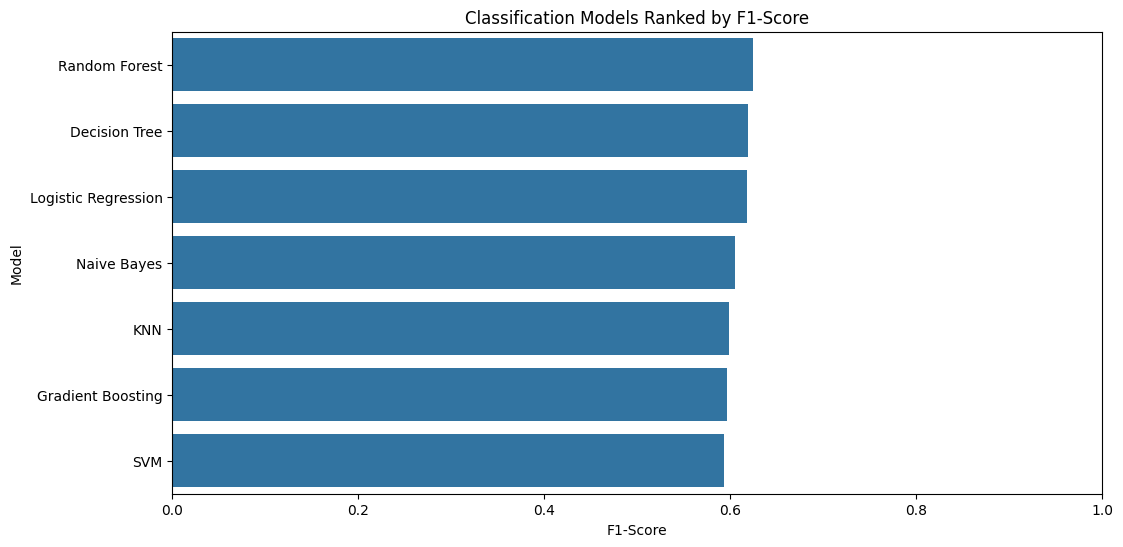

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="F1",
    y="Model"
)

plt.title("Classification Models Ranked by F1-Score")
plt.xlabel("F1-Score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

## And we compare the ROC-AUC:

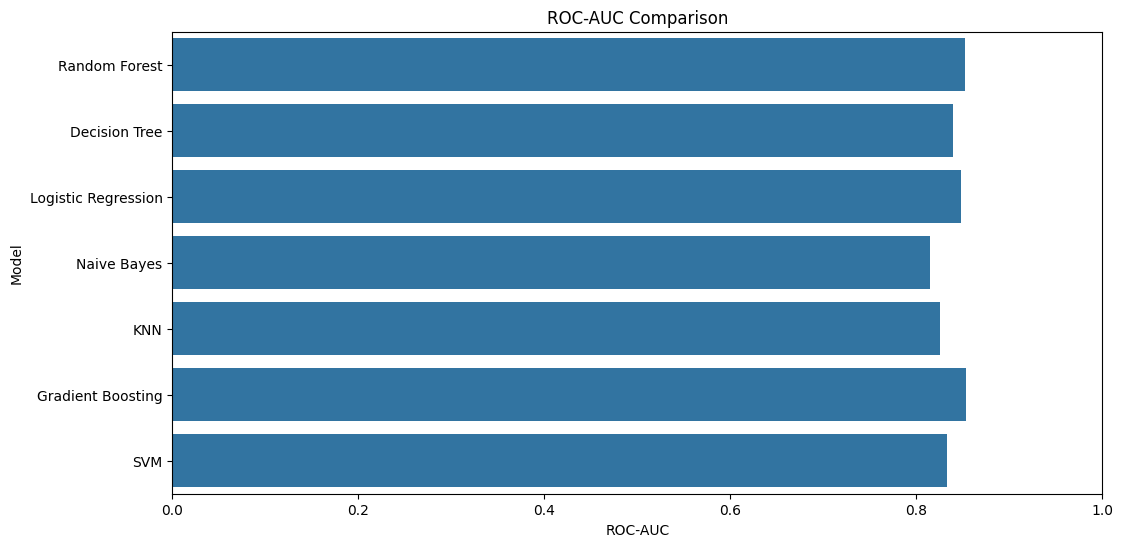

In [9]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="ROC_AUC",
    y="Model"
)

plt.title("ROC-AUC Comparison")
plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

## 9. Confusion Matrix and Classification Report

Recommended Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.54      0.73      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



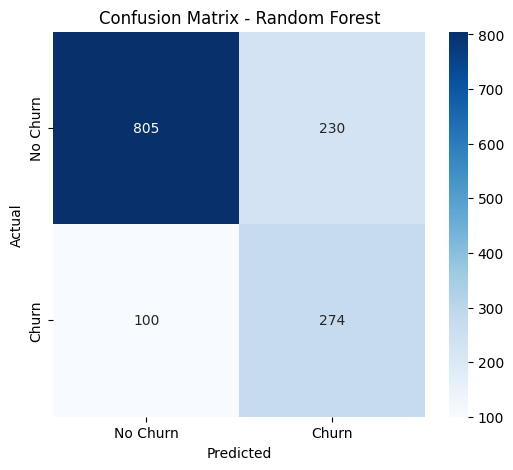

In [10]:
from sklearn.metrics import confusion_matrix, classification_report

best_name = recommended_name
best_model = recommended_model

pred = best_model.predict(X_test)

print("Recommended Model:", best_name)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

## 10. Save and verify the recommended churn model

In [11]:
import joblib
from pathlib import Path

# Select the recommended model
best_model = fitted_models[recommended_name]

# Save model
model_path = Path.cwd() / "churn_model.pkl"

joblib.dump(best_model, model_path, compress=3)

# Verify file
if model_path.exists() and model_path.stat().st_size > 0:

    print("Churn model saved successfully!")
    print("Recommended model:", recommended_name)
    print("File location:", model_path)
    print(
        f"File size: {model_path.stat().st_size / 1024:.2f} KB"
    )

else:
    raise FileNotFoundError("Churn model was not saved!")

# Load saved model
loaded_model = joblib.load(model_path)

# Verify loaded model predictions
original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

if np.array_equal(original_predictions, loaded_predictions):

    print("\nModel loaded and verified successfully!")
    print("Predictions are identical.")

else:
    raise ValueError("Model verification failed!")

Churn model saved successfully!
Recommended model: Random Forest
File location: /content/churn_model.pkl
File size: 4385.24 KB

Model loaded and verified successfully!
Predictions are identical.
